# Chapitre 6 - Cours 1 : découper les données, par plage de clés ou par hachage

Quand le volume de données ou le débit de requêtes dépasse ce qu'une machine peut
absorber, on découpe le jeu de données en morceaux, les **partitions**, et l'on place des
partitions différentes sur des nœuds différents. Chaque enregistrement appartient à une
seule partition ; chaque partition est en quelque sorte une petite base autonome. Le but
premier est la **scalabilité** : répartir données et requêtes sur de nombreux disques et
processeurs. Ce notebook couvre l'introduction du chapitre (avec l'encadré
*Terminological confusion*), la section *Partitioning and Replication* et la section
*Partitioning of Key-Value Data* jusqu'aux sous-sections *Partitioning by Key Range* et
*Partitioning by Hash of Key* (le rééquilibrage fait l'objet du cours 2).

**Plan.**

1. Partitionnement et réplication : deux mécanismes indépendants qui se combinent.
2. L'objectif : une répartition équitable, et ce que coûte le déséquilibre.
3. Le partitionnement par plage de clés : l'encyclopédie en volumes.
4. Le piège des horodatages : un point chaud qui se déplace avec le temps.
5. Le partitionnement par hachage : uniformité retrouvée, requêtes de plage perdues.

In [1]:
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

## 1. Partitionnement et réplication (section *Partitioning and Replication*)

Une base distribuée répartit ses données de deux façons complémentaires :

- la **réplication** (chapitre 5) garde **une copie des mêmes données** sur
  plusieurs nœuds, pour tolérer les pannes et servir plus de lectures ;
- le **partitionnement** découpe les données en **morceaux disjoints**
  et place des morceaux différents sur des nœuds différents, pour stocker plus et écrire
  plus vite que ne le permettrait une seule machine.

Les deux se combinent presque toujours : chaque partition est répliquée
sur plusieurs nœuds, si bien qu'un enregistrement appartient à **une seule**
partition mais vit sur **plusieurs** machines. Avec une réplication à
leader unique, chaque partition a son propre leader, et un même nœud est
leader pour certaines partitions et suiveur pour d'autres. Le
choix du découpage étant largement indépendant du choix de la réplication, le reste du
chapitre ignore la réplication.

**Vocabulaire.** Le même concept porte des noms différents selon les logiciels :
*partition* (Kafka), *shard* (MongoDB, Elasticsearch, SolrCloud), *region* (HBase),
*tablet* (Bigtable), *vnode* (Cassandra, Riak), *vBucket* (Couchbase)... Le livre emploie « partition » ; nous dirons de même « partition » et « partitionnement ».
Rien à voir, en revanche, avec une **partition réseau** (coupure du réseau entre des nœuds,
chapitre 8).

Calculons un placement typique : 4 nœuds, 8 partitions, facteur de
réplication 3. Le leader de la partition $p$ va sur le nœud $p \bmod 4$,
ses deux suiveurs sur les deux nœuds suivants.

In [2]:
N_NODES, N_SHARDS, RF = 4, 8, 3
placement = pd.DataFrame(
    [[("leader" if (p % N_NODES) == n else "suiveur" if (n - p) % N_NODES < RF else "")
      for n in range(N_NODES)] for p in range(N_SHARDS)],
    index=[f"P{p}" for p in range(N_SHARDS)], columns=[f"nœud {n}" for n in range(N_NODES)])
resume = pd.DataFrame({"leader de": (placement == "leader").sum(), "suiveur de": (placement == "suiveur").sum()})
display(placement.T)
resume.T

,P0,P1,P2,P3,P4,P5,P6,P7
nœud 0,leader,,suiveur,suiveur,leader,,suiveur,suiveur
nœud 1,suiveur,leader,,suiveur,suiveur,leader,,suiveur
nœud 2,suiveur,suiveur,leader,,suiveur,suiveur,leader,
nœud 3,,suiveur,suiveur,leader,,suiveur,suiveur,leader


,nœud 0,nœud 1,nœud 2,nœud 3
leader de,2,2,2,2
suiveur de,4,4,4,4


Chaque nœud est leader de 2 partitions et suiveur de 4 autres : les
écritures (qui vont au leader) sont réparties sur les quatre machines, et la perte d'un
nœud ne fait disparaître aucune donnée. Le diagramme ci-dessous dessine
les quatre premières partitions (P0 à P3) sur les quatre nœuds.

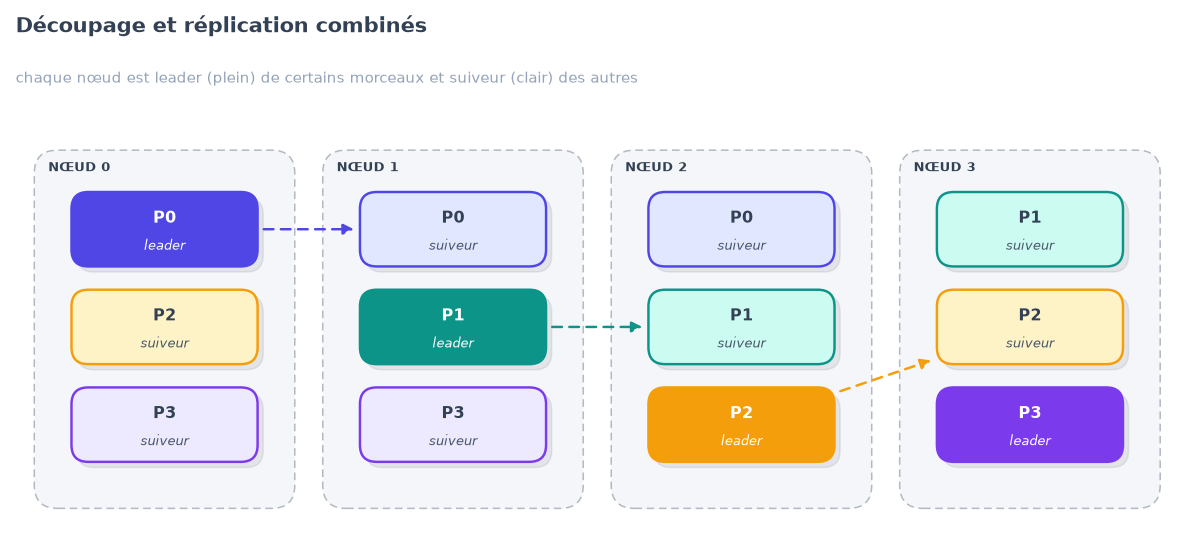

In [3]:
d = Diagram(12.6, 4.6, title="Découpage et réplication combinés",
            subtitle="chaque nœud est leader (plein) de certains morceaux et suiveur (clair) des autres")
colors = [INDIGO, TEAL, AMBER, VIOLET]
for n in range(N_NODES):
    x0 = 0.25 + n * 3.1
    d.group(x0, 0.2, x0 + 2.8, 4.05, f"nœud {n}", color=SLATE)
    row = 0
    for p in range(4):
        role = placement.iloc[p, n]
        if role:
            y = 3.2 - row * 1.05
            d.box(f"p{p}n{n}", x0 + 1.4, y, f"P{p}", sub=role, color=colors[p], w=2.0, h=0.8,
                  filled=(role == "leader"))
            row += 1
for p in range(4):
    lead = p % N_NODES
    for k in (1, 2):
        f = (lead + k) % N_NODES
        if abs(f - lead) == 1:   # flèches vers le voisin immédiat seulement, pour rester lisible
            d.arrow(f"p{p}n{lead}", f"p{p}n{f}", style="dashed", color=colors[p])
d.show()

Les flèches pointillées symbolisent le flux de réplication du leader vers un suiveur
voisin (les autres flux sont omis pour la lisibilité). Tout ce que le chapitre
5 dit de la réplication s'applique à chaque partition
séparément.

> **À retenir.** Réplication = copies identiques sur plusieurs nœuds ;
> partitionnement = morceaux disjoints sur des nœuds différents. On
> combine les deux : chaque enregistrement appartient à une seule
> partition, répliquée sur plusieurs nœuds.